In [451]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sales = pd.read_csv(r'C:\Python Learning\Python Learning\Diwali Sales Data.csv', encoding='latin1')
sales

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0,NaN,NaN
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0,NaN,NaN
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0,NaN,NaN
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0,NaN,NaN


In [452]:
sales.shape

(11251, 15)

Checking Null values and data types

In [453]:
sales.columns
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.3 MB


Removing 'Status' and 'Unnamed' columns that has only null values

In [454]:
sales.drop(columns = ['Status','unnamed1'], inplace = True)


Removing rows that have null values on the 'Amount' column. Since the number of null values in 'Amount' columns is very less, we are 
removing those rows from the data.

In [455]:
sales = sales.dropna(subset = ['Amount'])

In [456]:
sales.shape

(11239, 13)

In [457]:
sales['User_ID']=sales['User_ID'].astype(str)
sales['Age'] = sales['Age'].astype(str)
sales['Marital_Status'] = sales['Marital_Status'].astype(str)
sales.info()

<class 'pandas.DataFrame'>
Index: 11239 entries, 0 to 11250
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11239 non-null  str    
 1   Cust_name         11239 non-null  str    
 2   Product_ID        11239 non-null  str    
 3   Gender            11239 non-null  str    
 4   Age Group         11239 non-null  str    
 5   Age               11239 non-null  str    
 6   Marital_Status    11239 non-null  str    
 7   State             11239 non-null  str    
 8   Zone              11239 non-null  str    
 9   Occupation        11239 non-null  str    
 10  Product_Category  11239 non-null  str    
 11  Orders            11239 non-null  int64  
 12  Amount            11239 non-null  float64
dtypes: float64(1), int64(1), str(11)
memory usage: 1.2 MB


In [458]:
sales.describe()

,Orders,Amount
count,11239.000000,11239.000000
mean,2.489634,9453.610858
std,1.114967,5222.355869
min,1.000000,188.000000
25%,2.000000,5443.000000
50%,2.000000,8109.000000
75%,3.000000,12675.000000
max,4.000000,23952.000000


Checking for outliers

In [459]:
q1 = sales['Amount'].quantile(0.25)
q3 = sales['Amount'].quantile(0.75)
IQR = q3 - q1
IQR

np.float64(7232.0)

In [460]:
upper_bound = q3 + 1.5*IQR
lower_bound = q1 - 1.5*IQR

outliers = sales[(sales['Amount']<lower_bound) | (sales['Amount']>upper_bound)]
print("Upper_Bound:", upper_bound)
print("Lower_Bound:", lower_bound)
print("Number of outliers:",len(outliers))


Upper_Bound: 23523.0
Lower_Bound: -5405.0
Number of outliers: 19


Since the minimum amound is 188(check sales.info()), all 48 outliers should be greater than the upper bound as the maximum amount is 23952. Hence all 48 outliers lie between 21703 and 23952.

In [461]:
print(len(sales[sales['Amount']>upper_bound]))

High_value_sales = sales[sales['Amount']>upper_bound]
High_value_sales.head()

19


,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0


The above represents that the shop had 48 high value sales.

  Age Group     Amount
0      0-17   23912.00
1     18-25  118533.00
2     26-35  238279.99
3     46-50   23525.00
4     51-55   47136.00


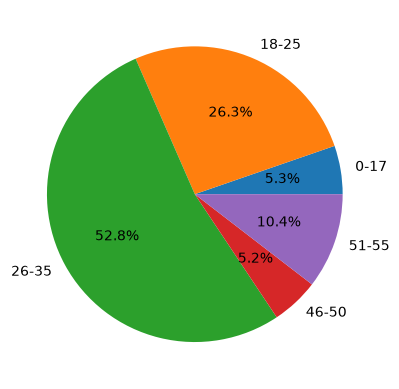

In [462]:
Age_Distribution_of_high_value_sales = High_value_sales.groupby('Age Group', as_index = False)['Amount'].sum()
print(Age_Distribution_of_high_value_sales)

plt.pie(Age_Distribution_of_high_value_sales['Amount'], labels=Age_Distribution_of_high_value_sales['Age Group'],autopct='%1.1f%%')
plt.show()

  Gender        Amount
0      F  23753.362727
1      M  23762.375000


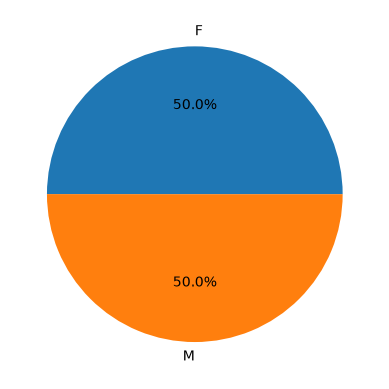

In [463]:
Gender_Distribution_of_high_value_sales = High_value_sales.groupby('Gender', as_index = False)['Amount'].mean()
print(Gender_Distribution_of_high_value_sales)

plt.pie(Gender_Distribution_of_high_value_sales['Amount'], labels=Gender_Distribution_of_high_value_sales['Gender'],autopct='%1.1f%%')
plt.show()

The above distribution indicates that among the high value sales, major sales have come from customers under 26-35 age bracket. Second highest is from customers under 18-25 age bracket.

High value sales by product category: Product_Category
Auto    451385.99
Name: Amount, dtype: float64


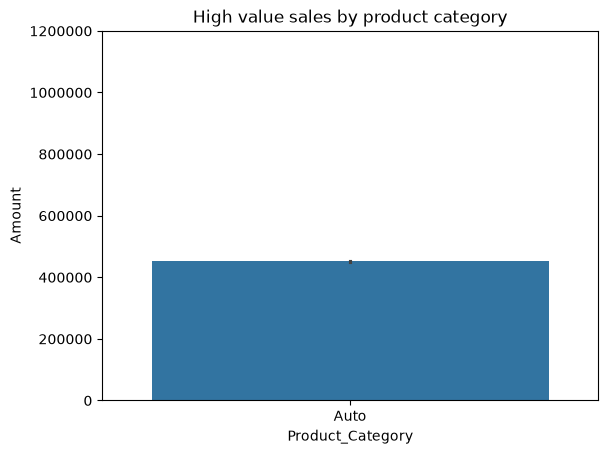

In [464]:
t = High_value_sales.groupby('Product_Category')['Amount'].sum()
print("High value sales by product category:",t)

sns.barplot(High_value_sales, x = High_value_sales['Product_Category'],y = High_value_sales['Amount'], estimator = np.sum)
plt.ticklabel_format(style='plain', axis = 'y')
plt.ylim(0,1200000)
plt.title('High value sales by product category')
plt.show()

Below graph shows the box plot of revenue. It shows the variablity and skewness towards the right indicating the outliers.

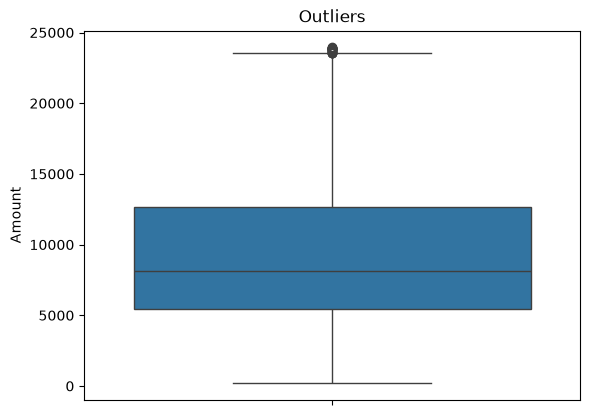

In [465]:
sns.boxplot(sales['Amount'])
plt.title('Outliers')
plt.show()

Below Histogram shows that the data is moderately skewed to the right indicating that the even though low value sales dominated, the high value sales were relatively higher as the value of skew is less than 1. Usually in retail sales, the skewness is generally greater than 1 as there are fewer or rare high value tickets/sales and way higher low value tickets.

Skewness of Amount: 0.5580257366658405


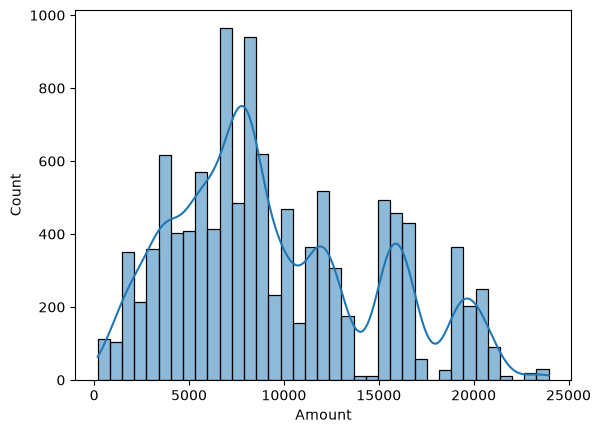

In [466]:
print("Skewness of Amount:", sales['Amount'].skew())

sns.histplot(sales['Amount'],kde=True)
plt.show()

Sales Comparison Betweeen Different Age Groups

In [467]:
sales.groupby('Age Group',as_index = False)['Amount'].describe()

,Age Group,count,mean,std,min,25%,50%,75%,max
0,0-17,296.0,9120.449324,4992.579673,396.0,5444.75,7975.0,12100.5,23912.0
1,18-25,1879.0,9175.482704,5166.589094,188.0,5374.00,8015.0,12024.5,23841.0
2,26-35,4541.0,9384.154138,5250.741044,367.0,5391.00,8100.0,12668.0,23952.0
3,36-45,2283.0,9699.954223,5264.770665,206.0,5905.00,8225.0,13068.0,23456.0
4,46-50,983.0,9367.084435,5103.668526,569.0,5445.00,8088.0,12320.5,23525.0
5,51-55,830.0,9953.586747,5238.155987,382.0,6090.00,8575.5,13158.5,23568.0
6,55+,427.0,9557.346604,5242.045774,568.0,5445.50,8187.0,12666.0,23513.0


  Age Group       Amount
0      0-17   2699653.00
1     18-25  17240732.00
2     26-35  42613443.94
3     36-45  22144995.49
4     46-50   9207844.00
5     51-55   8261477.00
6       55+   4080987.00


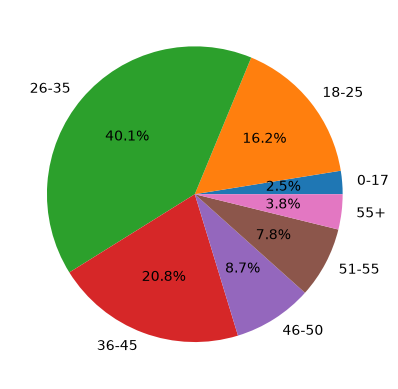

In [468]:
t = sales.groupby('Age Group',as_index = False)[['Amount']].sum()
print(t)
plt.pie(t['Amount'],labels=t['Age Group'],autopct='%1.1f%%')
plt.show()

Abover graph indicates that a major chunk of revenue is generated by customers under the age bracket of 26-35 followed by 18-25 during Diwali.

Below graph and table indicates the total transactions by Age Group and Gender. It shows that among all age group, female customers are predominantly higher than male customers.

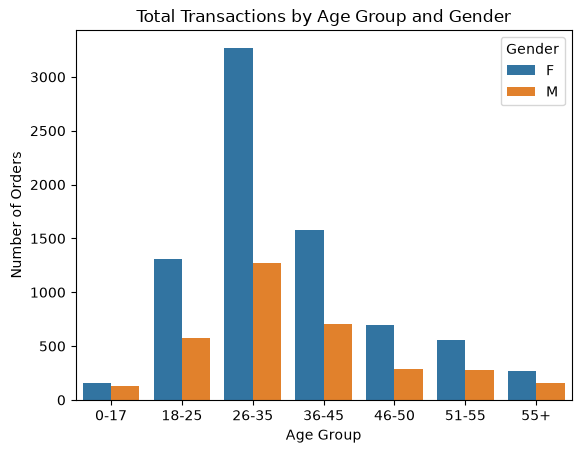

In [469]:
sns.countplot(sales, x = sales['Age Group'], hue =sales['Gender'],order= sales['Age Group'].sort_values())
plt.title('Total Transactions by Age Group and Gender')
plt.ylabel('Number of Orders')
plt.legend(title = 'Gender')
plt.show()

In [470]:
yt = sales.groupby('Gender', as_index=False)[['User_ID']].nunique()
yt

,Gender,User_ID
0,F,2697
1,M,1557


Below graph indicates almost 70% of the sales between the age group of 26-35 are from female customers. 

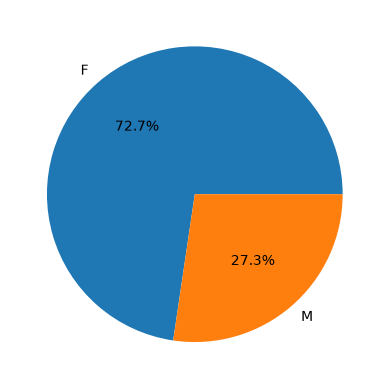

In [471]:
Youth = sales[sales['Age Group']== '26-35'].groupby('Gender', as_index= False)['Amount'].sum()
Youth

plt.pie(Youth['Amount'],labels=Youth['Gender'],autopct='%1.1f%%')
plt.show()

In [472]:
Youth_sales_mean = sales[sales['Age Group']== '26-35'].groupby('Gender', as_index= False)['Amount'].mean()
Youth_sales_mean

,Gender,Amount
0,F,9471.996005
1,M,9158.403302


Above table indicates that there is no significant difference between the average spending between male and female customers amoung the age group of 25-36. Hence the revenue dominance can be purely attributed to the frequency of female buyers.

In the overall sales revenue, major sales are generated from the female customers.

  Gender       Amount
0      F  74335856.43
1      M  31913276.00


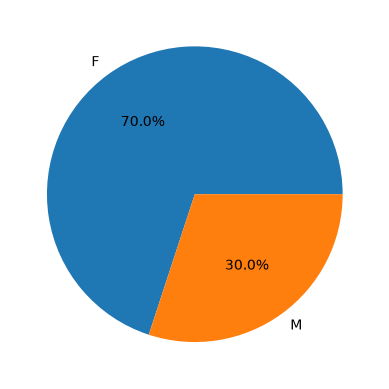

In [473]:
v = sales.groupby('Gender',as_index = False)[['Amount']].sum()
print(v)

plt.pie(v['Amount'],labels=v['Gender'],autopct='%1.1f%%')
plt.show()

Below table shows the number of orders by male and female customers. It also shows out of the whole sales records, female customers are twice the male customers.

In [474]:
orders_per_Gender = sales.groupby('Gender',as_index = False)[['Orders']].sum()
print(orders_per_Gender)

customer_demography = sales.groupby('Gender',as_index = False)[['User_ID']].count()
print(customer_demography)

  Gender  Orders
0      F   19548
1      M    8433
  Gender  User_ID
0      F     7832
1      M     3407


REVENUE COMPARISON AMONG DIFFERENT AGE GROUP

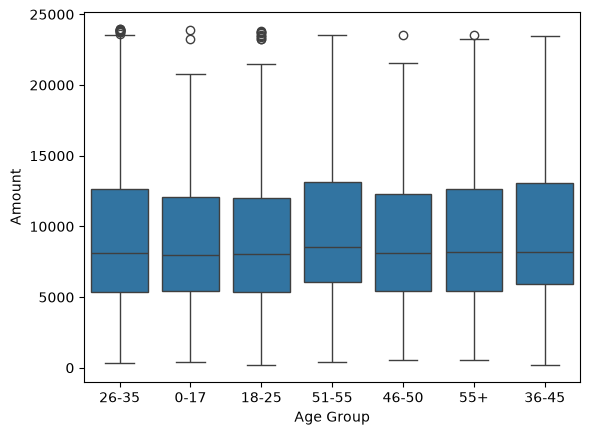

In [475]:
sns.boxplot(x = sales['Age Group'], y = sales['Amount'])
plt.show()

Above chart indicates that the median spending is more or less same for all the age group. Variability is also similar

SALES COMPARISON BETWEEN GENDER

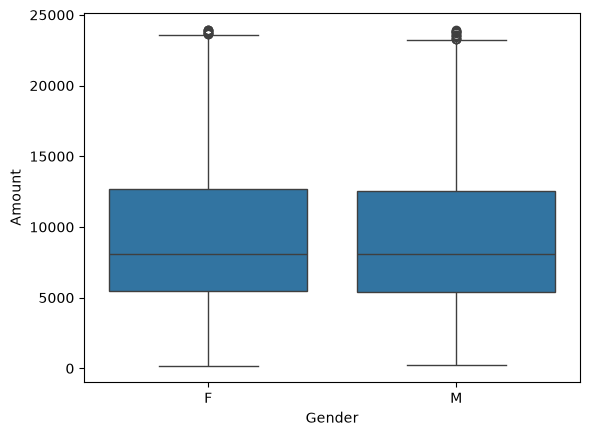

In [476]:
sns.boxplot(x = sales['Gender'], y = sales['Amount'])
plt.show()

The above graph indicates that the median revenue is almost similar for both male and female. Inorder to confirm this, hypothesis testing is also done below.

Sales Comparison against Marital Status

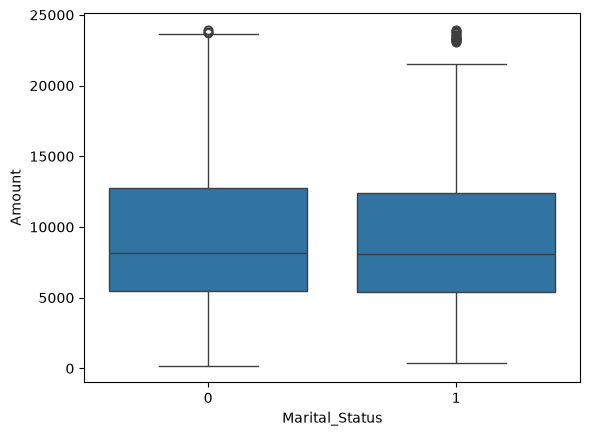

In [477]:
sns.boxplot(x = sales['Marital_Status'], y = sales['Amount'])
plt.show()

All the above graph indicates there is no significant difference in the median sales across all categories. Median sales is more or less the same among the genders, different age group and marital status. And mostly all graphs show variability.

Skewness of Amount: 0.5580257366658405


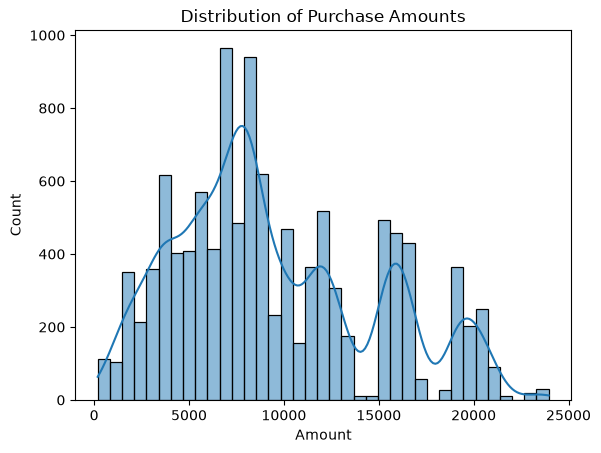

In [478]:
print("Skewness of Amount:", sales['Amount'].skew())

# Plot the distribution curve
sns.histplot(sales['Amount'], kde=True)
plt.title('Distribution of Purchase Amounts')
plt.show()

Hypothesis testing to check whether the tiny difference is real or if it is random luck. 
The box plot generated to compare the gender specific spending indiacted that there is no real difference between male and female spending. On an average, male and female spending is same. Inorder to conclude that this correct, we are double checking to look past the visual 'noise'.

In [479]:

Female_spending = sales[sales['Gender']== 'F']['Amount']
Male_spending = sales[sales['Gender']== 'M']['Amount']

from scipy import stats
t_stats,p_value = stats.ttest_ind(Female_spending,Male_spending,equal_var=False)
print('T_stat:', t_stats)
print('P_value:', p_value)

T_stat: 1.153606686461195
P_value: 0.24870454458846233


To understand if purchasing power per transaction significantly differs between male and female shoppers, an **Independent Two-Sample T-Test (Welch's T-Test)** was conducted on the `Amount` column.

**Null Hypothesis ($H_0$):** The mean transaction amount is equal for both female and male shoppers 

**Alternative Hypothesis ($H_1$):** The mean transaction amount differs significantly between female and male shoppers 

Since the p-value is greater than the significance level of 0.05 threshold, we fail to reject the null hypothesis.There is no statistically significant difference in the average individual amount spent per transaction between male and female. 

DEMOGRAPHIC REGION

       Zone       Amount
0   Central  41600873.45
3  Southern  26606668.98
4   Western  18373625.00
2  Northern  12618752.00
1   Eastern   7049213.00


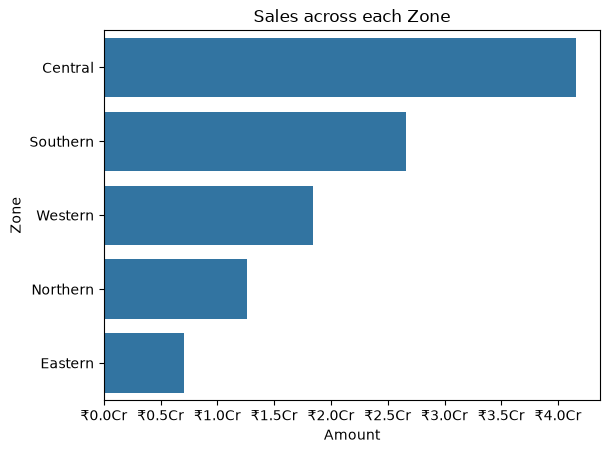

In [480]:
zone_wise_sales = sales.groupby('Zone', as_index=False)[['Amount']].sum().sort_values(by = 'Amount', ascending= False)
print(zone_wise_sales)
sns.barplot(zone_wise_sales, x = zone_wise_sales['Amount'], y= zone_wise_sales['Zone'])
import matplotlib.ticker as ticker
# 1. Turn off the scientific notation (gets rid of 1e7)
plt.ticklabel_format(style='plain', axis='x')
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/10000000:.1f}Cr'))
plt.title('Sales across each Zone')
plt.show()

In [481]:
state_wise = sales.groupby('State', as_index=False)[['Amount']].sum().sort_values(by = 'Amount', ascending= False)
state_wise.head()

,State,Amount
14,Uttar Pradesh,19374968.00
10,Maharashtra,14427543.00
7,Karnataka,13523540.00
2,Delhi,11603819.45
9,Madhya Pradesh,8101142.00


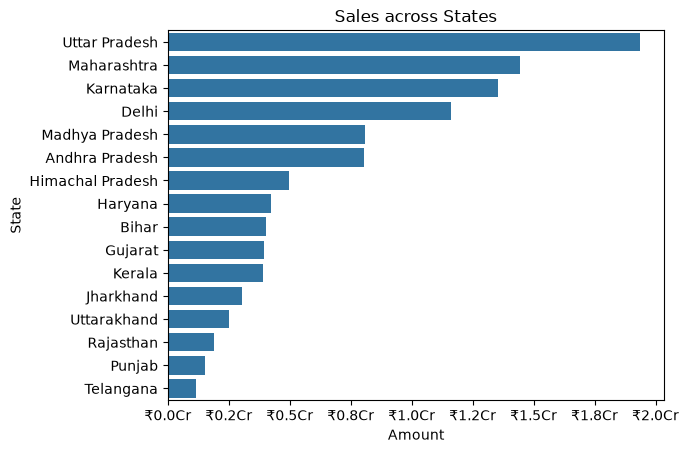

In [482]:
sns.barplot(state_wise, x = state_wise['Amount'], y=state_wise['State'])
import matplotlib.ticker as ticker
# 1. Turn off the scientific notation (gets rid of 1e7)
plt.ticklabel_format(style='plain', axis='x')
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/10000000:.1f}Cr'))
plt.title('Sales across States')
#plt.xlim(0,20000000)
plt.show()

KEY FINDINGS

### 1. The Volume vs. Value Paradox (Core Finding)
Our Independent T-test proves that individual purchasing power per transaction is identical between genders. Men and women spend similar amounts per order. Men and women spend similar amounts per order.
However, aggregate volume is massively dominated by female customers.Out of the total sales record, **7,832 transactions were driven by women compared to only 3,407 by men**. Women constitute the absolute majority of the customer footprint.
Marketing team must target female centric messaging as they are the high volume customers. since the small segment of male buyers still match women on a per-order value basis, marketing to men should focus on high-ticket product bundling (e.g., tech or automotive packages) to maximize revenue from their lower-frequency visits.

### 2. Core Target Persona
 **The Finding:** The **26–35 age group followed by 18-25 age group represents the absolute highest sales volume and total revenue category for the business, heavily dominated by the female demographic within this bracket.
  Ad creatives, festive discounts, and product curation/recommendation should be tailored specifically to the digital shopping habits and lifestyle preferences of this young professional demographic.

### 3. Geographic & Inventory Strategy
Holiday sales are heavily centralized in three major regions: **Uttar Pradesh, Maharashtra, and Karnataka**.
Prioritize supply chain logistics, festive inventory warehousing, and targeted local ad spend in these three power states well ahead of the holiday rush to minimize stockouts and maximize order fulfillment rates.

